# 🏥 Experiment 03: KTAS 결정 트리 구조 최적화 (`T_orig` vs `T_opt`) & N=300 A/B 본 평가
### 논리적 동치성 보존 기반 트리 리팩토링, 임상 안전성(Under-triage), 통계 검정 & 오류 사례 분석

* **평가 모델**: `Qwen2.5-32B-Instruct` (`temperature=0.0`, 공정성 보정된 동일 시스템 프롬프트 적용)
* **평가 대상**: 총 300건 (`Hotspot Top 20` 200건 + `일반/DNR 예외` 100건)


---
## Step 1. 환경 설정 및 300건 벤치마크 데이터셋 분포 확인


[+] 평가 케이스 로드 완료: 총 300건 | 최적화 트리 주호소: 326개


/home/meisteryi/문서/KTAS-LLM/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


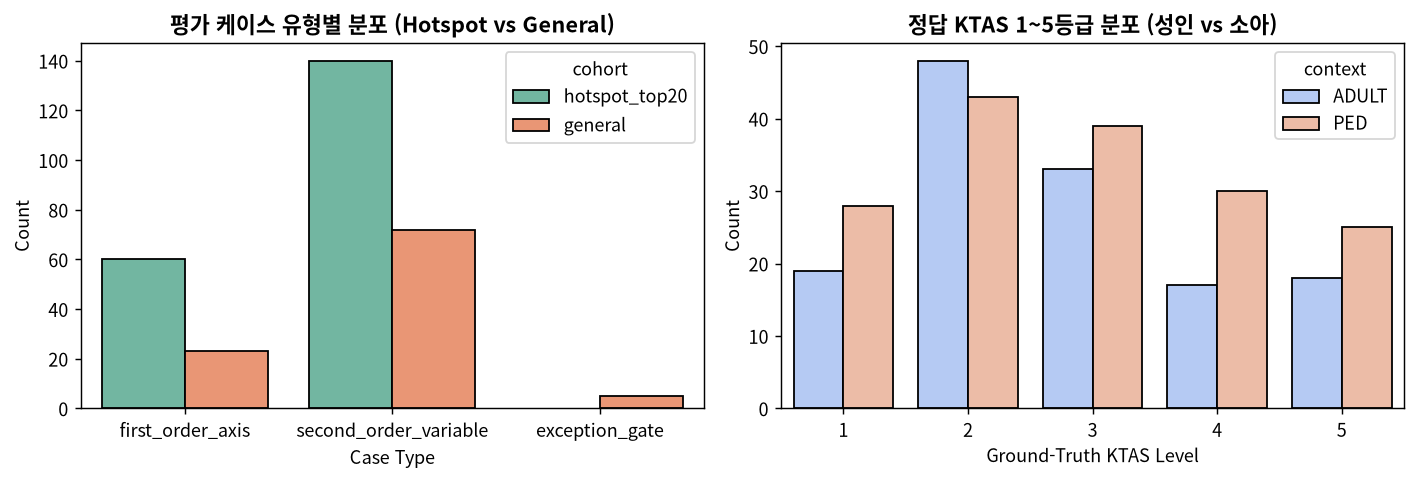

In [1]:
# Step 1: 환경 설정, 데이터 로드 및 벤치마크 분포 시각화
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

CWD = Path.cwd()
if (CWD / "src" / "benchmark").exists():
    EXP_ROOT = CWD
elif (CWD.parent / "src" / "benchmark").exists():
    EXP_ROOT = CWD.parent
else:
    EXP_ROOT = Path("/home/meisteryi/문서/KTAS-LLM/experiments/03_tree_structure_optimization")

sys.path.insert(0, str(EXP_ROOT / "src" / "benchmark"))
sys.path.insert(0, str(EXP_ROOT / "src" / "optimizer"))

from run_llm_benchmark import (
    InferenceBackend,
    build_ab_report,
    build_user_prompt,
    compute_metrics,
    load_orig_complaint_map,
    mcnemar_pvalue,
    parse_llm_json,
    serialize_t_opt_context,
    serialize_t_orig_context,
    wilcoxon_pvalue,
)

plt.rcParams["font.family"] = "Noto Sans CJK KR"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 10

RAW_DIR = EXP_ROOT / "data" / "raw"
OPT_JSON = EXP_ROOT / "data" / "optimized" / "ktas_optimized_tree.json"
CASES_JSON = EXP_ROOT / "data" / "benchmark" / "ktas_eval_cases.json"
OUT_JSONL = EXP_ROOT / "data" / "benchmark" / "ab_raw_results.jsonl"
REPORTS_DIR = EXP_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

with CASES_JSON.open("r", encoding="utf-8") as f:
    eval_cases = json.load(f)
with OPT_JSON.open("r", encoding="utf-8") as f:
    opt_data = json.load(f)

df_cases = pd.DataFrame([
    {
        "case_id": c["case_id"],
        "cohort": c["cohort"],
        "context": c["context"],
        "case_type": c["case_type"],
        "ktas_level": c["ground_truth_level"],
    }
    for c in eval_cases
])

print(f"[+] 평가 케이스 로드 완료: 총 {len(eval_cases)}건 | 최적화 트리 주호소: {len(opt_data['complaints'])}개")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), dpi=130)
sns.countplot(data=df_cases, x="case_type", hue="cohort", palette="Set2", edgecolor="black", ax=axes[0])
axes[0].set_title("평가 케이스 유형별 분포 (Hotspot vs General)", fontweight="bold")
axes[0].set_xlabel("Case Type")
axes[0].set_ylabel("Count")

sns.countplot(data=df_cases, x="ktas_level", hue="context", palette="coolwarm", edgecolor="black", ax=axes[1])
axes[1].set_title("정답 KTAS 1~5등급 분포 (성인 vs 소아)", fontweight="bold")
axes[1].set_xlabel("Ground-Truth KTAS Level")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()


---
## Step 2. `T_orig` vs `T_opt` LLM A/B 추론 실행 / 결과 로드 (`RUN_LIMIT = 0`: 전체 300건)


In [2]:
# Step 2: A/B 추론 실행 및 실시간 캐시 로드
RUN_LIMIT = 0     # 0: 전체 300건(600회) | 양수 N: 상위 N건
BACKEND = "auto"  # "auto", "hf", "openai"
BASE_URL = None
MODEL_ARG = ""

target_cases = eval_cases[:RUN_LIMIT] if RUN_LIMIT > 0 else eval_cases
target_ids = {c["case_id"] for c in target_cases}

existing_records = []
done_keys = set()
if OUT_JSONL.exists():
    with OUT_JSONL.open("r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                rec = json.loads(line)
                existing_records.append(rec)
                done_keys.add((rec["case_id"], rec["tree_variant"]))

orig_map = load_orig_complaint_map(RAW_DIR)
opt_map = {(c["context"], c["nacrs_code"], c["name"]): c for c in opt_data["complaints"]}

tasks = []
for c in target_cases:
    key = (c["context"], c["nacrs_code"], c["complaint_name"])
    if (c["case_id"], "T_orig") not in done_keys:
        tasks.append((c, "T_orig", serialize_t_orig_context(orig_map[key])))
    if (c["case_id"], "T_opt") not in done_keys:
        tasks.append((c, "T_opt", serialize_t_opt_context(opt_map[key])))

print(f"[*] 대상 케이스: {len(target_cases)}건 | 기존 완료: {len(done_keys)}회 | 신규 추론 필요: {len(tasks)}회")

if tasks:
    engine = InferenceBackend(BACKEND, MODEL_ARG, BASE_URL)
    with OUT_JSONL.open("a", encoding="utf-8") as f:
        for idx, (c, variant, tree_ctx) in enumerate(tasks, start=1):
            t0 = time.perf_counter()
            prompt = build_user_prompt(c, tree_ctx)
            raw_out, in_toks, out_toks = engine.generate(prompt)
            elapsed = time.perf_counter() - t0
            parsed = parse_llm_json(raw_out)
            rec = {
                "case_id": c["case_id"],
                "tree_variant": variant,
                "ground_truth_level": c["ground_truth_level"],
                "input_tokens": in_toks,
                "output_tokens": out_toks,
                "elapsed_sec": round(elapsed, 3),
                "parsed": parsed,
                "raw_output": raw_out,
            }
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            f.flush()
            existing_records.append(rec)

active_records = [r for r in existing_records if r["case_id"] in target_ids]
print(f"[+] 분석 대상 레코드: {len(active_records)}건")


[*] 대상 케이스: 300건 | 기존 완료: 600회 | 신규 추론 필요: 0회
[+] 분석 대상 레코드: 600건


---
## Step 3. 종합 & 군별 층화 비교 DataFrame (McNemar / Wilcoxon $p$-value 포함)


In [3]:
# Step 3: 전체(N=300) / Hotspot Top 20(N=200) / 일반·DNR(N=100) 층화 비교 및 통계 검정
cases_by_id = {c["case_id"]: c for c in target_cases}

def build_stratified_table(subset_name: str, recs: list[dict]):
    ro = [r for r in recs if r["tree_variant"] == "T_orig"]
    rp = [r for r in recs if r["tree_variant"] == "T_opt"]
    mo = compute_metrics(ro, cases_by_id)
    mp = compute_metrics(rp, cases_by_id)
    if not mo or not mp:
        return pd.DataFrame(), mo, mp

    vo, vp = mo["_vecs"], mp["_vecs"]
    p_acc = mcnemar_pvalue(vo["acc"], vp["acc"]) if vo["ordered_ids"] == vp["ordered_ids"] else None
    p_cu = mcnemar_pvalue(vo["crit_under"], vp["crit_under"]) if len(vo["crit_under"]) == len(vp["crit_under"]) else None
    p_ma = mcnemar_pvalue(vo["miss_all"], vp["miss_all"]) if len(vo["miss_all"]) == len(vp["miss_all"]) else None
    p_mc = mcnemar_pvalue(vo["miss_crit"], vp["miss_crit"]) if len(vo["miss_crit"]) == len(vp["miss_crit"]) else None
    p_ct = mcnemar_pvalue(vo["cite"], vp["cite"]) if len(vo["cite"]) == len(vp["cite"]) else None
    p_tot = wilcoxon_pvalue(vo["tot_toks"], vp["tot_toks"]) if vo["ordered_ids"] == vp["ordered_ids"] else None

    rows = [
        ("최종 등급 정확도 (% ↑)", mo["acc"], mp["acc"], p_acc),
        ("Macro-F1 (% ↑)", mo["macro_f1"], mp["macro_f1"], None),
        ("치명적 과소평가율 (1~2➔3~5, % ↓)", mo["crit_under_triage"], mp["crit_under_triage"], p_cu),
        ("일반 과소평가율 (pred > gt, % ↓)", mo["gen_under_triage"], mp["gen_under_triage"], None),
        ("과대평가율 (pred < gt, % ↓)", mo["over_triage"], mp["over_triage"], None),
        ("전체 1차 축 누락률 (% ↓)", mo["missing_first_all"], mp["missing_first_all"], p_ma),
        ("핵심 1차 활력징후 누락률 (% ↓)", mo["missing_first_crit"], mp["missing_first_crit"], p_mc),
        ("근거 규칙 일치율 (% ↑)", mo["rule_cite_acc"], mp["rule_cite_acc"], p_ct),
        ("평균 입력 토큰", mo["avg_in"], mp["avg_in"], None),
        ("평균 출력(추론) 토큰", mo["avg_out"], mp["avg_out"], None),
        ("환자당 총 토큰 (↓)", mo["avg_tot"], mp["avg_tot"], p_tot),
    ]
    df = pd.DataFrame([
        {
            "군(Cohort)": subset_name,
            "지표": name,
            "T_orig": round(v0, 2),
            "T_opt": round(v1, 2),
            "Delta": round(v1 - v0, 2),
            "p-value": (f"{pv:.2e}" if pv < 0.001 else f"{pv:.4f}") if pv is not None else "-",
        }
        for name, v0, v1, pv in rows
    ])
    return df, mo, mp

hs_recs = [r for r in active_records if cases_by_id[r["case_id"]]["cohort"] == "hotspot_top20"]
gen_recs = [r for r in active_records if cases_by_id[r["case_id"]]["cohort"] == "general"]

df_all, mo_all, mp_all = build_stratified_table(f"전체 (N={len({r['case_id'] for r in active_records})})", active_records)
df_hs, mo_hs, mp_hs = build_stratified_table(f"Hotspot Top 20 (N={len({r['case_id'] for r in hs_recs})})", hs_recs)
df_gen, mo_gen, mp_gen = build_stratified_table(f"일반/DNR (N={len({r['case_id'] for r in gen_recs})})", gen_recs)

for title, d in [("전체 코호트", df_all), ("Hotspot Top 20 코호트", df_hs), ("일반 / DNR 코호트", df_gen)]:
    if not d.empty:
        print(f"=== {title} ===")
        display(d)

(REPORTS_DIR / "ab_benchmark_results.md").write_text(
    build_ab_report(active_records, cases_by_id, "Qwen2.5-32B-Instruct"), encoding="utf-8"
)


=== 전체 코호트 ===


,군(Cohort),지표,T_orig,T_opt,Delta,p-value
0,전체 (N=300),최종 등급 정확도 (% ↑),97.33,92.67,-4.67,0.0043
1,전체 (N=300),Macro-F1 (% ↑),97.57,93.01,-4.56,-
2,전체 (N=300),"치명적 과소평가율 (1~2➔3~5, % ↓)",2.17,7.97,5.80,0.0386
3,전체 (N=300),"일반 과소평가율 (pred > gt, % ↓)",2.00,5.67,3.67,-
4,전체 (N=300),"과대평가율 (pred < gt, % ↓)",0.33,1.00,0.67,-
5,전체 (N=300),전체 1차 축 누락률 (% ↓),32.00,26.18,-5.82,0.0206
6,전체 (N=300),핵심 1차 활력징후 누락률 (% ↓),4.73,1.82,-2.91,0.0215
7,전체 (N=300),근거 규칙 일치율 (% ↑),96.31,93.55,-2.76,0.1796
8,전체 (N=300),평균 입력 토큰,1077.68,807.82,-269.86,-
9,전체 (N=300),평균 출력(추론) 토큰,178.63,184.97,6.34,-


=== Hotspot Top 20 코호트 ===


,군(Cohort),지표,T_orig,T_opt,Delta,p-value
0,Hotspot Top 20 (N=200),최종 등급 정확도 (% ↑),97.00,95.00,-2.00,0.3438
1,Hotspot Top 20 (N=200),Macro-F1 (% ↑),97.02,95.05,-1.97,-
2,Hotspot Top 20 (N=200),"치명적 과소평가율 (1~2➔3~5, % ↓)",2.08,6.25,4.17,0.2188
3,Hotspot Top 20 (N=200),"일반 과소평가율 (pred > gt, % ↓)",2.00,4.00,2.00,-
4,Hotspot Top 20 (N=200),"과대평가율 (pred < gt, % ↓)",0.50,1.00,0.50,-
5,Hotspot Top 20 (N=200),전체 1차 축 누락률 (% ↓),36.00,29.50,-6.50,0.0259
6,Hotspot Top 20 (N=200),핵심 1차 활력징후 누락률 (% ↓),5.50,2.50,-3.00,0.0703
7,Hotspot Top 20 (N=200),근거 규칙 일치율 (% ↑),96.43,96.43,0.00,1.0000
8,Hotspot Top 20 (N=200),평균 입력 토큰,1172.23,857.49,-314.75,-
9,Hotspot Top 20 (N=200),평균 출력(추론) 토큰,180.43,191.50,11.07,-


=== 일반 / DNR 코호트 ===


,군(Cohort),지표,T_orig,T_opt,Delta,p-value
0,일반/DNR (N=100),최종 등급 정확도 (% ↑),98.00,88.00,-10.00,0.0063
1,일반/DNR (N=100),Macro-F1 (% ↑),98.08,89.03,-9.05,-
2,일반/DNR (N=100),"치명적 과소평가율 (1~2➔3~5, % ↓)",2.38,11.90,9.52,0.2188
3,일반/DNR (N=100),"일반 과소평가율 (pred > gt, % ↓)",2.00,9.00,7.00,-
4,일반/DNR (N=100),"과대평가율 (pred < gt, % ↓)",0.00,1.00,1.00,-
5,일반/DNR (N=100),전체 1차 축 누락률 (% ↓),21.33,17.33,-4.00,0.5811
6,일반/DNR (N=100),핵심 1차 활력징후 누락률 (% ↓),2.67,0.00,-2.67,0.5000
7,일반/DNR (N=100),근거 규칙 일치율 (% ↑),96.10,88.31,-7.79,0.1094
8,일반/DNR (N=100),평균 입력 토큰,888.58,708.50,-180.08,-
9,일반/DNR (N=100),평균 출력(추론) 토큰,175.04,171.91,-3.13,-


3439

---
## Step 4. 4-패널 대시보드 & 군별(Hotspot vs 일반) 개선 폭 비교 차트


[+] 대시보드 저장 완료: /home/meisteryi/문서/KTAS-LLM/experiments/03_tree_structure_optimization/reports/ab_benchmark_dashboard.png


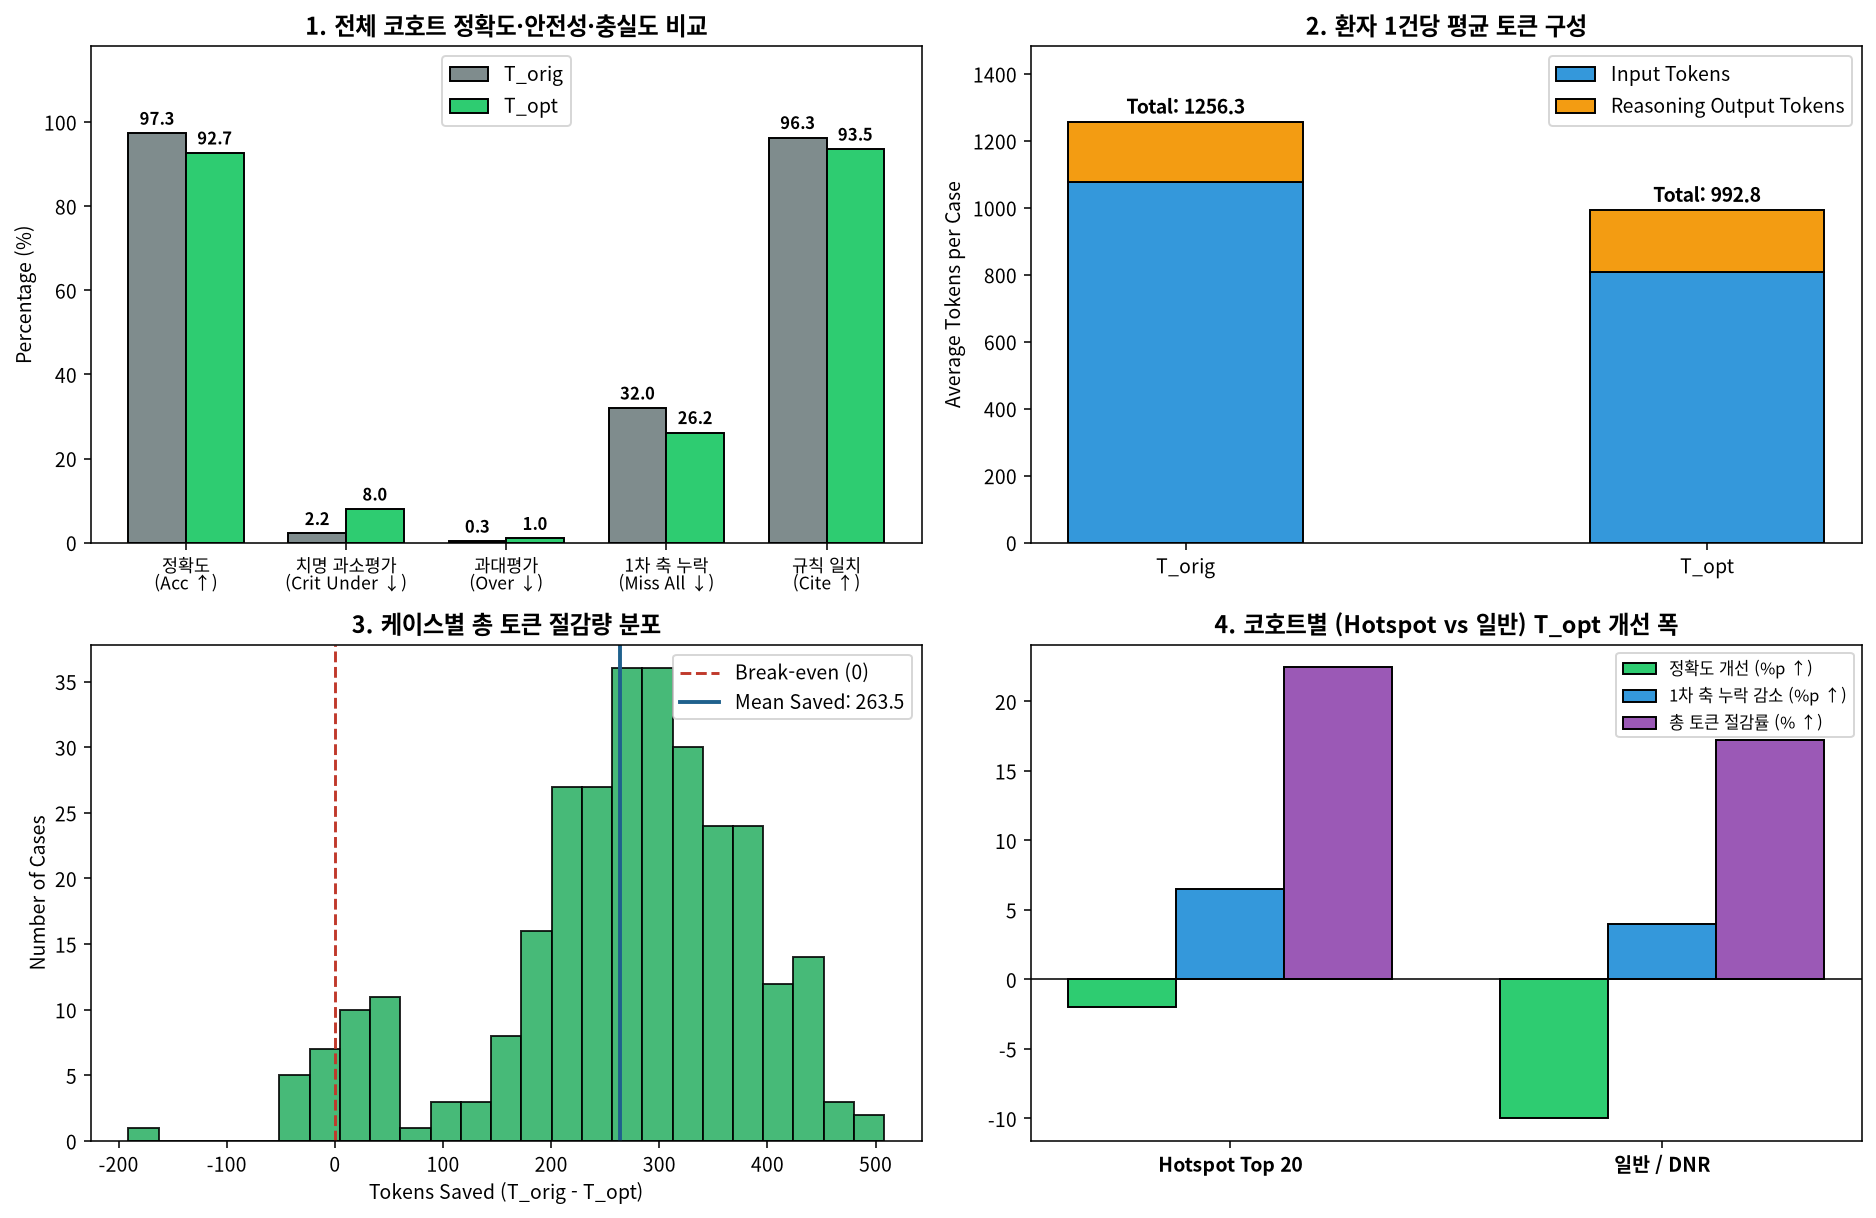

In [4]:
# Step 4: 4-패널 대시보드 + 군별 개선 폭 비교 차트 렌더링
r_orig = [r for r in active_records if r["tree_variant"] == "T_orig"]
r_opt = [r for r in active_records if r["tree_variant"] == "T_opt"]

fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.8), dpi=140)

# 1) 정확도 / 안전성 / 충실도
ax = axes[0, 0]
m_labels = ["정확도\n(Acc ↑)", "치명 과소평가\n(Crit Under ↓)", "과대평가\n(Over ↓)", "1차 축 누락\n(Miss All ↓)", "규칙 일치\n(Cite ↑)"]
v_orig = [mo_all["acc"], mo_all["crit_under_triage"], mo_all["over_triage"], mo_all["missing_first_all"], mo_all["rule_cite_acc"]]
v_opt = [mp_all["acc"], mp_all["crit_under_triage"], mp_all["over_triage"], mp_all["missing_first_all"], mp_all["rule_cite_acc"]]
x = np.arange(len(m_labels))
w = 0.36
ax.bar(x - w / 2, v_orig, w, label="T_orig", color="#7f8c8d", edgecolor="black")
ax.bar(x + w / 2, v_opt, w, label="T_opt", color="#2ecc71", edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels(m_labels, fontsize=9)
ax.set_ylim(0, 118)
ax.set_ylabel("Percentage (%)")
ax.set_title("1. 전체 코호트 정확도·안전성·충실도 비교", fontweight="bold")
ax.legend()
for i in range(len(m_labels)):
    ax.text(i - w / 2, v_orig[i] + 2, f"{v_orig[i]:.1f}", ha="center", fontsize=8.5, fontweight="bold")
    ax.text(i + w / 2, v_opt[i] + 2, f"{v_opt[i]:.1f}", ha="center", fontsize=8.5, fontweight="bold")

# 2) 토큰 구성 스택 바 차트
ax = axes[0, 1]
in_vals = [mo_all["avg_in"], mp_all["avg_in"]]
out_vals = [mo_all["avg_out"], mp_all["avg_out"]]
ax.bar(["T_orig", "T_opt"], in_vals, width=0.45, label="Input Tokens", color="#3498db", edgecolor="black")
ax.bar(["T_orig", "T_opt"], out_vals, width=0.45, bottom=in_vals, label="Reasoning Output Tokens", color="#f39c12", edgecolor="black")
ax.set_ylabel("Average Tokens per Case")
ax.set_title("2. 환자 1건당 평균 토큰 구성", fontweight="bold")
ax.set_ylim(0, max(mo_all["avg_tot"], mp_all["avg_tot"]) * 1.18)
ax.legend()
for idx, (iv, ov) in enumerate(zip(in_vals, out_vals)):
    ax.text(idx, iv + ov + 25, f"Total: {iv+ov:.1f}", ha="center", fontweight="bold")

# 3) 케이스별 총 토큰 절감량 분포
ax = axes[1, 0]
orig_tok_map = {r["case_id"]: r["input_tokens"] + r["output_tokens"] for r in r_orig}
opt_tok_map = {r["case_id"]: r["input_tokens"] + r["output_tokens"] for r in r_opt}
common_ids = sorted(set(orig_tok_map) & set(opt_tok_map))
saved_toks = [orig_tok_map[cid] - opt_tok_map[cid] for cid in common_ids]
ax.hist(saved_toks, bins=min(25, max(5, len(saved_toks) // 4)), color="#27ae60", edgecolor="black", alpha=0.85)
ax.axvline(0, color="#c0392b", linestyle="--", linewidth=1.5, label="Break-even (0)")
ax.axvline(np.mean(saved_toks), color="#1f618d", linestyle="-", linewidth=2, label=f"Mean Saved: {np.mean(saved_toks):.1f}")
ax.set_xlabel("Tokens Saved (T_orig - T_opt)")
ax.set_ylabel("Number of Cases")
ax.set_title("3. 케이스별 총 토큰 절감량 분포", fontweight="bold")
ax.legend()

# 4) Hotspot Top 20 vs 일반/DNR 군별 개선 폭 비교
ax = axes[1, 1]
if mo_hs and mp_hs and mo_gen and mp_gen:
    cohorts = ["Hotspot Top 20", "일반 / DNR"]
    acc_delta = [mp_hs["acc"] - mo_hs["acc"], mp_gen["acc"] - mo_gen["acc"]]
    miss_delta = [mo_hs["missing_first_all"] - mp_hs["missing_first_all"], mo_gen["missing_first_all"] - mp_gen["missing_first_all"]]
    tok_red_pct = [
        (mo_hs["avg_tot"] - mp_hs["avg_tot"]) / mo_hs["avg_tot"] * 100.0,
        (mo_gen["avg_tot"] - mp_gen["avg_tot"]) / mo_gen["avg_tot"] * 100.0,
    ]
    xc = np.arange(len(cohorts))
    wc = 0.25
    ax.bar(xc - wc, acc_delta, wc, label="정확도 개선 (%p ↑)", color="#2ecc71", edgecolor="black")
    ax.bar(xc, miss_delta, wc, label="1차 축 누락 감소 (%p ↑)", color="#3498db", edgecolor="black")
    ax.bar(xc + wc, tok_red_pct, wc, label="총 토큰 절감률 (% ↑)", color="#9b59b6", edgecolor="black")
    ax.set_xticks(xc)
    ax.set_xticklabels(cohorts, fontweight="bold")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title("4. 코호트별 (Hotspot vs 일반) T_opt 개선 폭", fontweight="bold")
    ax.legend(fontsize=8.5)
else:
    ax.text(0.5, 0.5, "코호트별 비교를 위해 양쪽 코호트 데이터가 필요합니다.", ha="center", va="center")
    ax.axis("off")

plt.tight_layout()
dash_path = REPORTS_DIR / "ab_benchmark_dashboard.png"
plt.savefig(dash_path, bbox_inches="tight", dpi=150)
print(f"[+] 대시보드 저장 완료: {dash_path}")
plt.show()


---
## Step 5. 오류 사례 비교 뷰어 (Error Case Inspector: `T_orig` 오류 vs `T_opt` 방어)


In [5]:
# Step 5: T_orig에서 오류(정답 불일치/과소평가/누락)가 발생하고 T_opt가 방어한 대표 사례 출력
orig_by_id = {r["case_id"]: r for r in r_orig}
opt_by_id = {r["case_id"]: r for r in r_opt}

inspector_cases = []
for cid in sorted(set(orig_by_id) & set(opt_by_id)):
    c = cases_by_id[cid]
    gt = c["ground_truth_level"]
    po = orig_by_id[cid]["parsed"]
    pp = opt_by_id[cid]["parsed"]
    lo = int(po.get("final_ktas_level", 0))
    lp = int(pp.get("final_ktas_level", 0))

    # 1순위: T_orig 오분류/과소평가 & T_opt 정답
    if lo != gt and lp == gt:
        inspector_cases.append((0, cid))
    # 2순위: T_orig 1차 축 누락 & T_opt 완전 커버
    elif len(po.get("checked_first_order_axes", [])) < len(pp.get("checked_first_order_axes", [])):
        inspector_cases.append((1, cid))

inspector_cases.sort()
print(f"[*] 발굴된 대표 대조 사례 수: {len(inspector_cases)}건 (상위 최대 5건 출력)")

for _, cid in inspector_cases[:5]:
    c = cases_by_id[cid]
    ro, rp = orig_by_id[cid], opt_by_id[cid]
    po, pp = ro["parsed"], rp["parsed"]
    print("=" * 90)
    print(f"📌 [{cid}] ({c['cohort']}) {c['context']} {c['complaint_name']} ({c['nacrs_code']}) | 정답 KTAS: {c['ground_truth_level']}단계")
    print(f"   환자 입력: {c['patient_presentation']}")
    print("-" * 90)
    print(f"  [T_orig] 판정={po.get('final_ktas_level')}단계 | 토큰={ro['input_tokens']}+{ro['output_tokens']} | 1차축={po.get('checked_first_order_axes')}")
    print(f"           추론={po.get('reasoning_steps')}")
    print(f"           근거={po.get('matched_rule_text')}")
    print(f"  [T_opt ] 판정={pp.get('final_ktas_level')}단계 | 토큰={rp['input_tokens']}+{rp['output_tokens']} | 1차축={pp.get('checked_first_order_axes')}")
    print(f"           추론={pp.get('reasoning_steps')}")
    print(f"           근거={pp.get('matched_rule_text')}")


[*] 발굴된 대표 대조 사례 수: 89건 (상위 최대 5건 출력)
📌 [EVAL_GEN_037] (general) PED 혈변 / 흑색변 (260) | 정답 KTAS: 2단계
   환자 입력: [만 11세 소아] 주호소: 혈변 / 흑색변 (NACRS 260). 1차 활력징후는 특이 위험 징후 없으나, 문진 및 진찰상 다음 2차 세부 소견이 확인됨: 직장 출혈.
------------------------------------------------------------------------------------------
  [T_orig] 판정=3단계 | 토큰=1037+239 | 1차축=['1차_활력징후', '출혈_양상']
           추론=['주호소는 혈변 / 흑색변 (NACRS 260)으로, 1차 고려사항 중 충족하는 항목이 없습니다.', '2차 고려사항을 순차적으로 평가합니다.', '소아 1차 활력징후 1단계, 2단계, 3단계를 만족하지 않음.', '출혈성 질환(위급)이나 출혈성 질환(경도/중등도)을 평가합니다.', '직장 출혈이 확인되어, 2차 고려사항 3번 (KTAS 3단계)에 해당합니다.']
           근거=(KTAS 3단계) 출혈성 질환(경도/중등도)
  [T_opt ] 판정=2단계 | 토큰=750+168 | 1차축=['1차_활력징후', '출혈_양상']
           추론=['1차_활력징후에서 특이 위험 징후가 없으므로 1단계와 2단계는 배제되고 3단계로 분류.', '출혈_양상에서 많은 양의 흑색변 또는 직장 출혈이 확인되어 2단계로 분류.']
           근거=[출혈_양상] 2단계:많은 양의 흑색변 또는 직장 출혈
📌 [EVAL_HS_018] (hotspot_top20) ADULT 출산 후 문제 (6주 이내) (459) | 정답 KTAS: 2단계
   환자 입력: [만 33세 가임기 여성] 주호소: 출산 후 문제 (6주 이내) (NACRS 459). 1차 활력징후는 특이 위험 징후 없으나, 문진 및 진찰상 다음 2차